# SafeFlow — D12 simple time-series baselines

Evaluate **all available D12 years and stations**, with a separate 30-minute-ahead speed model for each station. Persistence, simple exponential smoothing (SES), and autoregressive Ridge use the same validation observations. Autocorrelation is a training-only diagnostic, not a forecast.

Input layout: `data/D12 YYYY/pems_parquet/station_5min/d12_text_station_5min_YYYY_MM_DD.parquet`, with yearly `pems_parquet_stations.csv` metadata. D7 and combined-district analysis are deferred.

Run all cells from the repository root or `notebooks/`. Dependencies: pandas, numpy, pyarrow, matplotlib, scikit-learn. Loading all years may take several minutes. Missing days remain missing; no interpolation is performed. PeMS timestamps are treated as local wall-clock times. Duplicate station/timestamp records (including fall daylight-saving repeats) are averaged and counted, since these files do not identify UTC offsets.

In [ ]:
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results" / "d12_simple_timeseries"
DISTRICT = 12
YEARS = None  # None: discover all D12 year directories
STATION_IDS = None  # None: evaluate every station, with no freeway/direction restriction
SAMPLING_MIN, FORECAST_MIN = 5, 30
FORECAST_STEPS = FORECAST_MIN // SAMPLING_MIN
TARGET_MIN_OBSERVED = 80
INPUT_MIN_OBSERVED = None  # when set, mask low-quality current AND lagged inputs
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15
FOLD_WINDOWS = [
    ("2023-07-01", "2024-01-01"),
    ("2024-01-01", "2024-07-01"),
    ("2024-07-01", "2025-01-01"),
    ("2025-01-01", "2025-07-01"),
]
TEST_WINDOW = ("2025-07-01", "2026-01-01")
LAG_MINUTES = [0, 5, 10, 15, 30, 60]
CANDIDATE_ALPHAS = [0.05, 0.10, 0.20, 0.30, 0.50, 0.70, 0.90]
assert FORECAST_MIN % SAMPLING_MIN == 0
assert 0 < TRAIN_FRAC < TRAIN_FRAC + VAL_FRAC < 1
assert len(FOLD_WINDOWS) >= 1


## 1. Discover daily files and yearly station metadata
The inventory reports missing calendar days explicitly. Metadata retain their source year, because station attributes may change.

In [2]:
year_dirs = sorted(p for p in DATA_DIR.glob(f"D{DISTRICT} *")
                   if p.is_dir() and p.name.split()[-1].isdigit()
                   and (YEARS is None or int(p.name.split()[-1]) in YEARS))
files, inventory, metadata_parts = [], [], []
for directory in year_dirs:
    year = int(directory.name.split()[-1])
    daily = sorted((directory / "pems_parquet" / "station_5min").glob(
        f"d{DISTRICT:02d}_text_station_5min_{year}_*.parquet"))
    if not daily:
        raise FileNotFoundError(f"No daily Parquet files in {directory}")
    dates = pd.DatetimeIndex([pd.Timestamp(p.stem[-10:].replace("_", "-")) for p in daily])
    missing = pd.date_range(f"{year}-01-01", f"{year}-12-31").difference(dates)
    inventory.append(dict(year=year, files=len(daily), first=dates.min(), last=dates.max(),
                          missing_days=len(missing), missing_dates=", ".join(missing.strftime("%Y-%m-%d"))))
    files.extend(daily)
    metadata_file = directory / "pems_parquet_stations.csv"
    if metadata_file.exists():
        metadata_parts.append(pd.read_csv(metadata_file).assign(source_year=year))
if not files:
    raise FileNotFoundError(f"No D{DISTRICT} daily files found under {DATA_DIR}")
inventory = pd.DataFrame(inventory)
station_metadata = pd.concat(metadata_parts, ignore_index=True) if metadata_parts else pd.DataFrame()
display(inventory)
display(station_metadata.head())

,year,files,first,last,missing_days,missing_dates
0,2023,365,2023-01-01,2023-12-31,0,
1,2024,366,2024-01-01,2024-12-31,0,
2,2025,363,2025-01-01,2025-12-31,2,"2025-11-28, 2025-11-29"


,ID,District,Fwy,Dir,Type,Abs_PM,State_PM,Latitude,Longitude,Lanes,Name,source_year
0,1205041,12,5,N,FR,99.801,27.55,33.719297,-117.794408,1,JAMBOREE 1,2023
1,1205043,12,5,N,HV,99.801,27.55,33.719297,-117.794408,1,JAMBOREE 1,2023
2,1205045,12,5,N,ML,99.801,27.55,33.719297,-117.794408,5,JAMBOREE 1,2023
3,1205035,12,5,N,OR,99.801,27.55,33.719297,-117.794408,1,JAMBOREE 1,2023
4,1205069,12,5,N,HV,99.811,27.56,33.719391,-117.794541,1,JAMBOREE 2,2023


## 2. Load only speed and observation quality
Read one daily file at a time and reshape into compact float32 time-by-station matrices. No lane columns or large multi-year long table are retained. All stations in the observation files are included, even if metadata are absent.

In [3]:
import pyarrow.parquet as pq

# Canonical names used by the D12 Parquet files.
TIMESTAMP_COL, STATION_COL = "timestamp", "station"
SPEED_COL, OBSERVED_COL = "speed", "pct_observed"
columns = [TIMESTAMP_COL, STATION_COL, SPEED_COL, OBSERVED_COL]
def read_station_day(file):
    """Read physical Parquet columns and normalize legacy PeMS names."""
    aliases = {
        TIMESTAMP_COL: ("timestamp",),
        STATION_COL: ("station", "stationid"),
        SPEED_COL: ("speed", "avgspeed"),
        OBSERVED_COL: ("pctobserved", "observed", "percentobserved"),
    }
    normalize = lambda name: "".join(ch for ch in str(name).casefold() if ch.isalnum())
    try:
        parquet = pq.ParquetFile(file)
        available = parquet.schema_arrow.names
        rename = {}
        for canonical, candidates in aliases.items():
            matches = [name for name in available if normalize(name) in candidates]
            if len(matches) != 1:
                raise ValueError(f"Expected one column for {canonical!r}; found {matches}. Available columns: {available}")
            rename[matches[0]] = canonical
        return parquet.read(columns=list(rename)).to_pandas().rename(columns=rename)[columns]
    except Exception as exc:
        raise ValueError(f"Cannot load station observations from {file}: {exc}") from exc

speed_parts, observed_parts = [], []
duplicate_rows = 0
for number, file in enumerate(files, 1):
    daily = read_station_day(file)
    daily[TIMESTAMP_COL] = pd.to_datetime(daily[TIMESTAMP_COL], errors="raise")
    if daily[[TIMESTAMP_COL, STATION_COL]].isna().any().any():
        raise ValueError(f"Missing timestamp/station key in {file}")
    if STATION_IDS is not None:
        daily = daily.loc[daily[STATION_COL].isin(STATION_IDS)].copy()
    for column in [SPEED_COL, OBSERVED_COL]:
        daily[column] = pd.to_numeric(daily[column], errors="coerce").astype("float32")
    daily[SPEED_COL] = daily[SPEED_COL].where(np.isfinite(daily[SPEED_COL]) & (daily[SPEED_COL] >= 0))
    daily[OBSERVED_COL] = daily[OBSERVED_COL].where(daily[OBSERVED_COL].between(0, 100))
    duplicate_rows += int(daily.duplicated([TIMESTAMP_COL, STATION_COL]).sum())
    grouped = daily.groupby([TIMESTAMP_COL, STATION_COL])[[SPEED_COL, OBSERVED_COL]].mean()
    speed_parts.append(grouped[SPEED_COL].unstack())
    observed_parts.append(grouped[OBSERVED_COL].unstack())
    if number % 100 == 0 or number == len(files):
        print(f"Loaded {number}/{len(files)} files", flush=True)
speed = pd.concat(speed_parts).sort_index()
observed = pd.concat(observed_parts).sort_index()
del speed_parts, observed_parts, daily, grouped
duplicate_rows += int(speed.index.duplicated().sum())
if speed.index.has_duplicates:
    speed = speed.groupby(level=0).mean()
    observed = observed.groupby(level=0).mean()
if speed.empty:
    raise ValueError("No observations match the requested stations")
full_index = pd.date_range(speed.index.min(), speed.index.max(), freq=f"{SAMPLING_MIN}min")
if not speed.index.isin(full_index).all():
    raise ValueError("Source timestamps are not on the expected five-minute grid")
speed = speed.reindex(full_index).astype("float32")
observed = observed.reindex(index=full_index, columns=speed.columns).astype("float32")
speed.index.name = observed.index.name = TIMESTAMP_COL
print("Grid:", speed.shape, "Date range:", full_index.min(), "to", full_index.max())
print("Duplicate records collapsed:", duplicate_rows)
display(pd.DataFrame({"speed_coverage": speed.notna().mean(),
                      "mean_observed": observed.mean()}).rename_axis("station"))

Loaded 100/1094 files
Loaded 200/1094 files
Loaded 300/1094 files
Loaded 400/1094 files
Loaded 500/1094 files
Loaded 600/1094 files
Loaded 700/1094 files
Loaded 800/1094 files
Loaded 900/1094 files
Loaded 1000/1094 files
Loaded 1094/1094 files
Grid: (315648, 161) Date range: 2023-01-01 00:00:00 to 2025-12-31 23:55:00
Duplicate records collapsed: 125


,speed_coverage,mean_observed
station,,
1205035,0.000000,42.930695
1205041,0.000000,0.000000
1205043,0.996230,42.930374
1205045,0.996230,32.299892
1205069,0.996233,26.288960
...,...,...
1216517,0.996233,88.256020
1216522,0.000000,88.255699
1216538,0.996230,83.877655


## 3. Temporal validation folds
The feature notebook uses four temporal validation windows: July 2023 to Dec 2023, Jan 2024 to Jun 2024, Jul 2024 to Dec 2024, and Jan 2025 to Jun 2025. Each validation window uses all preceding observations for training, and the final six months of 2025 remain a sealed holdout. Origins whose +30-minute labels cross a split boundary are purged.

Missing values remain on the exact grid, so lags and targets always represent elapsed five-minute steps. Quality filters apply to future labels and optionally every input. All three models are scored on the same complete-lag validation rows within each fold.

In [4]:
horizon = pd.Timedelta(minutes=FORECAST_MIN)
folds = []

for val_start, val_end in FOLD_WINDOWS:
    val_start = pd.Timestamp(val_start)
    val_end = pd.Timestamp(val_end)
    training_candidates = full_index[(full_index >= full_index.min()) & (full_index + horizon < val_start)]
    val_candidates = full_index[(full_index >= val_start) & (full_index + horizon < val_end)]
    if len(training_candidates) == 0 or len(val_candidates) == 0:
        continue

    tune_boundary = training_candidates[int(len(training_candidates) * 0.80)]
    folds.append({
        "val_start": val_start,
        "val_end": val_end,
        "train_mask": (full_index >= full_index.min()) & (full_index + horizon < val_start),
        "val_mask": (full_index >= val_start) & (full_index + horizon < val_end),
        "tune_boundary": tune_boundary,
        "train_index": training_candidates,
        "val_index": val_candidates,
    })

holdout_start = pd.Timestamp(TEST_WINDOW[0])
holdout_end = pd.Timestamp(TEST_WINDOW[1])
holdout_mask = (full_index >= holdout_start) & (full_index + horizon < holdout_end)
print("Fold windows:", [(fold["val_start"].strftime("%Y-%m-%d"), fold["val_end"].strftime("%Y-%m-%d")) for fold in folds])
print("Sealed holdout origins from:", holdout_start, "to before:", holdout_end)


Fold windows: [('2023-07-01', '2024-01-01'), ('2024-01-01', '2024-07-01'), ('2024-07-01', '2025-01-01'), ('2025-01-01', '2025-07-01')]
Sealed holdout origins from: 2025-07-01 00:00:00 to before: 2026-01-01 00:00:00


C:\Users\abhis\AppData\Local\Temp\ipykernel_54236\413369143.py:1: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  horizon = pd.Timedelta(minutes=FORECAST_MIN)


In [6]:
metric_rows, coverage_rows, acf_rows = [], [], []
example = None
example_station = None

for position, station_id in enumerate(speed.columns, 1):
    raw = speed[station_id]
    inputs = raw if INPUT_MIN_OBSERVED is None else raw.where(observed[station_id] >= INPUT_MIN_OBSERVED)
    features = pd.DataFrame(
        {f"speed_lag_{minutes}min": inputs.shift(minutes // SAMPLING_MIN) for minutes in LAG_MINUTES}
    )
    target = raw.shift(-FORECAST_STEPS)
    valid_target = target.notna()
    if TARGET_MIN_OBSERVED is not None:
        valid_target &= observed[station_id].shift(-FORECAST_STEPS) >= TARGET_MIN_OBSERVED

    feature_mask = features.notna().all(axis=1)
    for fold in folds:
        train_mask = fold["train_mask"] & valid_target & feature_mask
        val_mask = fold["val_mask"] & valid_target & feature_mask
        train_index = full_index[train_mask]
        val_index = full_index[val_mask]
        tune_index = train_index[train_index >= fold["tune_boundary"]]
        status = (
            "evaluated"
            if len(train_index) >= 20 and len(val_index) > 0 and len(tune_index) > 0
            else "insufficient eligible data"
        )
        coverage_rows.append(
            dict(
                station=station_id,
                fold=fold["val_start"].strftime("%Y-%m-%d"),
                train_rows=len(train_index),
                validation_rows=len(val_index),
                tuning_rows=len(tune_index),
                speed_coverage=raw.notna().mean(),
                status=status,
            )
        )
        if status != "evaluated":
            continue

        tuning_errors = []
        for alpha in CANDIDATE_ALPHAS:
            level = inputs.loc[inputs.index < fold["val_start"]].ewm(
                alpha=alpha, adjust=False, ignore_na=True
            ).mean()
            tuning_errors.append((target.loc[tune_index] - level.loc[tune_index]).abs().mean())
        best_alpha = CANDIDATE_ALPHAS[int(np.argmin(tuning_errors))]

        level = inputs.loc[inputs.index < fold["val_end"]].ewm(
            alpha=best_alpha, adjust=False, ignore_na=True
        ).mean()
        ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
        ridge.fit(features.loc[train_index], target.loc[train_index])

        predictions = pd.DataFrame(
            {
                "actual": target.loc[val_index],
                "Persistence": inputs.loc[val_index],
                "SES": level.loc[val_index],
                "Autoregressive Ridge": ridge.predict(features.loc[val_index]),
            }
        )

        for model in ["Persistence", "SES", "Autoregressive Ridge"]:
            errors = predictions[model] - predictions["actual"]
            metric_rows.append(
                dict(
                    station=station_id,
                    fold=fold["val_start"].strftime("%Y-%m-%d"),
                    model=model,
                    n=len(errors),
                    absolute_error_sum=errors.abs().sum(),
                    squared_error_sum=(errors ** 2).sum(),
                    MAE_mph=errors.abs().mean(),
                    RMSE_mph=np.sqrt((errors ** 2).mean()),
                    ses_alpha=best_alpha,
                )
            )

        training_speed = inputs.loc[inputs.index < fold["val_start"]]
        for lag in [1, 2, 3, 6, 12, 24, 72, 144, 288]:
            acf_rows.append(
                dict(
                    station=station_id,
                    fold=fold["val_start"].strftime("%Y-%m-%d"),
                    lag_minutes=lag * SAMPLING_MIN,
                    autocorrelation=training_speed.autocorr(lag=lag),
                )
            )

        if example is None:
            example, example_station = predictions, station_id

    if position % 25 == 0:
        print(f"Processed {position}/{len(speed.columns)} stations", flush=True)

coverage = pd.DataFrame(coverage_rows)
station_metrics = pd.DataFrame(metric_rows)
acf_table = pd.DataFrame(acf_rows)
display(coverage)
if station_metrics.empty:
    raise ValueError("No station has enough eligible training/tuning/validation data; inspect coverage and quality thresholds")


Processed 25/161 stations
Processed 50/161 stations
Processed 75/161 stations
Processed 100/161 stations
Processed 125/161 stations
Processed 150/161 stations


,station,fold,train_rows,validation_rows,tuning_rows,speed_coverage,status
0,1205035,2023-07-01,0,0,0,0.00000,insufficient eligible data
1,1205035,2024-01-01,0,0,0,0.00000,insufficient eligible data
2,1205035,2024-07-01,0,0,0,0.00000,insufficient eligible data
3,1205035,2025-01-01,0,0,0,0.00000,insufficient eligible data
4,1205041,2023-07-01,0,0,0,0.00000,insufficient eligible data
...,...,...,...,...,...,...,...
639,1216545,2025-01-01,160035,51836,41912,0.99623,evaluated
640,1216582,2023-07-01,0,0,0,0.99623,insufficient eligible data
641,1216582,2024-01-01,0,0,0,0.99623,insufficient eligible data
642,1216582,2024-07-01,0,0,0,0.99623,insufficient eligible data


## 4. Compare validation performance
Pooled MAE/RMSE weight each eligible station-time forecast equally; macro MAE weights each evaluated station equally. Coverage lists every station, including those skipped for insufficient data. These metrics describe rolling 30-minute forecasts with current measurements available at every origin.

,n,stations,absolute_error_sum,squared_error_sum,macro_MAE_mph,MAE_mph,RMSE_mph,MAE_improvement_vs_persistence_pct
model,,,,,,,,
SES,12459979,90,2.831137e+07,2.464333e+08,2.301152,2.272184,4.447245,1.420083
Persistence,12459979,90,2.871920e+07,2.493100e+08,2.338941,2.304916,4.473127,0.000000
Autoregressive Ridge,12459979,90,2.943837e+07,2.263881e+08,2.349717,2.362634,4.262537,-2.504116


,station,fold,model,n,absolute_error_sum,squared_error_sum,MAE_mph,RMSE_mph,ses_alpha
0,1205043,2023-07-01,Persistence,33219,137976.203125,2.431822e+06,4.153533,8.556036,0.9
1,1205043,2023-07-01,SES,33219,138857.898522,2.462418e+06,4.180075,8.609692,0.9
2,1205043,2023-07-01,Autoregressive Ridge,33219,153892.078125,2.205736e+06,4.632652,8.148610,0.9
3,1205045,2023-07-01,Persistence,28210,136004.703125,1.342988e+06,4.821152,6.899769,0.5
4,1205045,2023-07-01,SES,28210,132356.357053,1.332400e+06,4.691824,6.872515,0.5
5,1205045,2023-07-01,Autoregressive Ridge,28210,134022.406250,1.234453e+06,4.750883,6.615089,0.5
6,1205069,2023-07-01,Persistence,46808,183935.781250,3.331799e+06,3.929580,8.436831,0.9
7,1205069,2023-07-01,SES,46808,185413.962119,3.378186e+06,3.961160,8.495359,0.9
8,1205069,2023-07-01,Autoregressive Ridge,46808,207781.171875,2.969795e+06,4.439010,7.965319,0.9
9,1205069,2024-01-01,Persistence,3762,16627.898438,3.312411e+05,4.419962,9.383453,0.9


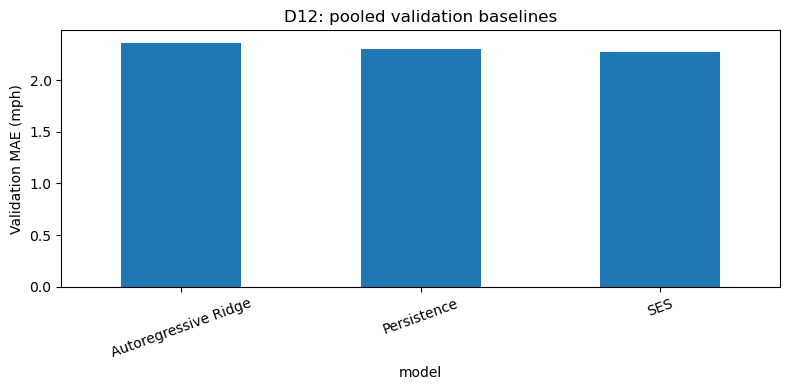

,mean,median,count
lag_minutes,,,
5,0.973754,0.976198,326
10,0.948798,0.953771,326
15,0.925749,0.932808,326
30,0.867463,0.882473,326
60,0.773701,0.788305,326
120,0.593689,0.599573,326
360,0.057474,0.024736,326
720,-0.273141,-0.294540,326
1440,0.712269,0.762300,326


In [7]:
metrics = station_metrics.groupby("model").agg(
    n=("n", "sum"), stations=("station", "nunique"),
    absolute_error_sum=("absolute_error_sum", "sum"), squared_error_sum=("squared_error_sum", "sum"),
    macro_MAE_mph=("MAE_mph", "mean"))
metrics["MAE_mph"] = metrics["absolute_error_sum"] / metrics["n"]
metrics["RMSE_mph"] = np.sqrt(metrics["squared_error_sum"] / metrics["n"])
baseline = metrics.loc["Persistence", "MAE_mph"]
metrics["MAE_improvement_vs_persistence_pct"] = (baseline - metrics["MAE_mph"]) / baseline * 100 if baseline else np.nan
display(metrics.sort_values("MAE_mph"))
display(station_metrics.head(15))
metrics["MAE_mph"].plot.bar(rot=20, ylabel="Validation MAE (mph)", title="D12: pooled validation baselines", figsize=(8, 4))
plt.tight_layout()
plt.show()
display(acf_table.groupby("lag_minutes")["autocorrelation"].agg(["mean", "median", "count"]))

C:\Users\abhis\AppData\Local\Temp\ipykernel_54236\51355990.py:1: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  window = example.loc[example.index < example.index.min() + pd.Timedelta(days=2)]


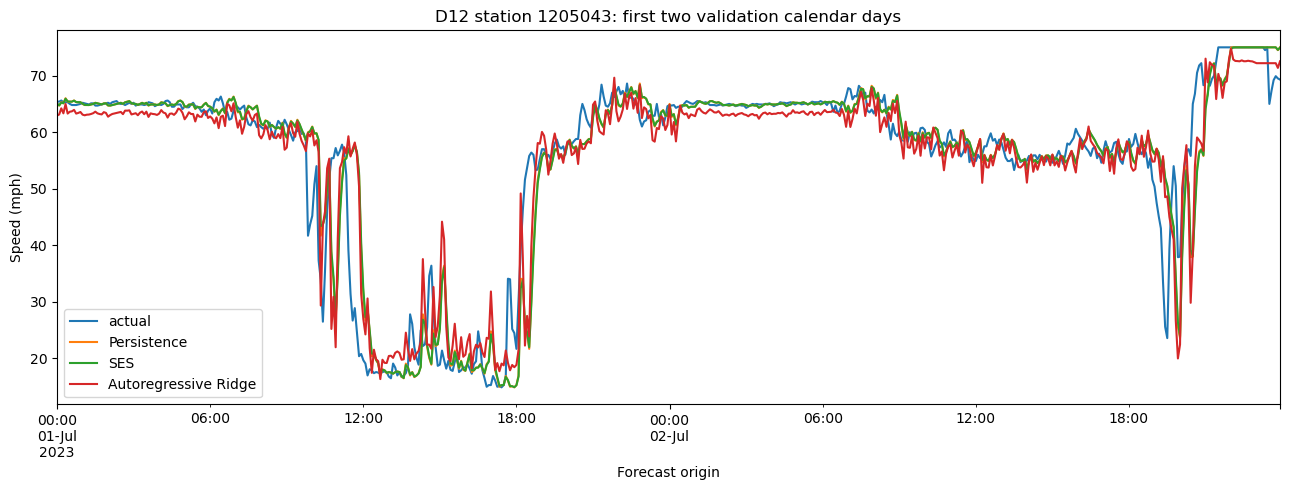

In [8]:
window = example.loc[example.index < example.index.min() + pd.Timedelta(days=2)]
window.plot(figsize=(13, 5), ylabel="Speed (mph)", xlabel="Forecast origin",
            title=f"D12 station {example_station}: first two validation calendar days")
plt.tight_layout()
plt.show()

## 5. Save results and configuration
A timestamped run directory prevents overwriting different quality-threshold runs. Test data remain unevaluated.

In [9]:
run_dir = RESULTS_DIR / datetime.now().strftime("%Y-%m-%d_%H%M%S_%f")
run_dir.mkdir(parents=True, exist_ok=False)
metrics.to_csv(run_dir / "validation_metrics.csv")
station_metrics.to_csv(run_dir / "station_validation_metrics.csv", index=False)
coverage.to_csv(run_dir / "station_coverage.csv", index=False)
inventory.to_csv(run_dir / "file_inventory.csv", index=False)
station_metadata.to_csv(run_dir / "station_metadata.csv", index=False)
acf_table.to_csv(run_dir / "training_autocorrelation.csv", index=False)
config = dict(
    district=DISTRICT,
    years=inventory["year"].tolist(),
    files=len(files),
    station_ids=None if STATION_IDS is None else list(STATION_IDS),
    sampling_minutes=SAMPLING_MIN,
    forecast_minutes=FORECAST_MIN,
    target_min_observed=TARGET_MIN_OBSERVED,
    input_min_observed=INPUT_MIN_OBSERVED,
    train_fraction=TRAIN_FRAC,
    validation_fraction=VAL_FRAC,
    fold_windows=[(str(start), str(end)) for start, end in FOLD_WINDOWS],
    holdout_window=[str(holdout_start), str(holdout_end)],
    lag_minutes=LAG_MINUTES,
    candidate_alphas=CANDIDATE_ALPHAS,
    duplicate_records_collapsed=duplicate_rows,
)
(run_dir / "configuration.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Saved validation results:", run_dir)


Saved validation results: c:\Erdos\Project\safeflow\results\d12_simple_timeseries\2026-10-24_173452_792115


## Interpretation and next steps
- Compare pooled and station-level errors: district averages can hide poor performance at individual stations.
- Persistence is the reference; SES can suppress noise but lag congestion transitions. Ridge tests whether recent speed history adds information.
- Autocorrelation uses training observations only. Missing data and low coverage affect which station-time forecasts can be evaluated.
- Repeat with target observation thresholds of 100, 80, 50, and 0; compare sample sizes alongside errors. SES carries its prior level across missing observations.
- Inspect congestion onset and recovery separately before moving to more complex models.
- D7 and combined-district analysis are future steps. Keep station series separate when adding districts; do not concatenate stations into one time series.

In [13]:
# ---------------------------------------------------------
# Traffic-regime summary for the worked example station
# ---------------------------------------------------------

if "example" not in globals() or "example_station" not in globals():
    raise NameError("Run the validation notebook cells before this summary; 'example' and 'example_station' are not available.")

CONGESTION_THRESHOLD = 45.0
REGIMES = [
    "Free → Free",
    "Free → Congested",
    "Congested → Congested",
    "Congested → Free",
]

station_id = int(example_station)
current_speed = speed[station_id].loc[example.index]
actual_speed = example["actual"]
model_names = ["Persistence", "SES", "Autoregressive Ridge"]

regime_df = pd.DataFrame({
    "current_speed": current_speed,
    "actual": actual_speed,
    "traffic_regime": np.select(
        [
            (current_speed >= CONGESTION_THRESHOLD) & (actual_speed >= CONGESTION_THRESHOLD),
            (current_speed >= CONGESTION_THRESHOLD) & (actual_speed < CONGESTION_THRESHOLD),
            (current_speed < CONGESTION_THRESHOLD) & (actual_speed < CONGESTION_THRESHOLD),
            (current_speed < CONGESTION_THRESHOLD) & (actual_speed >= CONGESTION_THRESHOLD),
        ],
        [
            "Free → Free",
            "Free → Congested",
            "Congested → Congested",
            "Congested → Free",
        ],
        default="Unknown",
    )
})

rows = []
for model in model_names:
    if model not in example.columns:
        continue
    for regime in REGIMES:
        subset = regime_df.loc[regime_df["traffic_regime"] == regime, ["actual"]].copy()
        subset["prediction"] = example.loc[subset.index, model]
        subset = subset.dropna()
        if subset.empty:
            continue
        rows.append({
            "Model": model,
            "Traffic regime": regime,
            "N": len(subset),
            "MAE (mph)": mean_absolute_error(subset["actual"], subset["prediction"]),
            "RMSE (mph)": np.sqrt(mean_squared_error(subset["actual"], subset["prediction"])),
        })

regime_metrics = pd.DataFrame(rows)
if regime_metrics.empty:
    raise ValueError("No valid traffic-regime rows exist for the example station; loosen the thresholds or inspect the example fit.")

display(regime_metrics.round(2))


,Model,Traffic regime,N,MAE (mph),RMSE (mph)
0,Persistence,Free → Free,22995,1.71,2.88
1,Persistence,Free → Congested,1295,24.78,25.96
2,Persistence,Congested → Congested,7639,4.28,6.91
3,Persistence,Congested → Free,1290,26.29,27.90
4,SES,Free → Free,22995,1.72,2.91
5,SES,Free → Congested,1295,24.86,26.04
6,SES,Congested → Congested,7639,4.33,7.00
7,SES,Congested → Free,1290,26.46,28.05
8,Autoregressive Ridge,Free → Free,22995,2.29,3.06
9,Autoregressive Ridge,Free → Congested,1295,23.57,24.81


In [14]:
# MAE comparison table
mae_table = regime_metrics.pivot(
    index="Model",
    columns="Traffic regime",
    values="MAE (mph)"
)

display(mae_table.round(2))

Traffic regime,Congested → Congested,Congested → Free,Free → Congested,Free → Free
Model,,,,
Autoregressive Ridge,5.43,22.71,23.57,2.29
Persistence,4.28,26.29,24.78,1.71
SES,4.33,26.46,24.86,1.72


In [15]:
# RMSE comparison table
rmse_table = regime_metrics.pivot(
    index="Model",
    columns="Traffic regime",
    values="RMSE (mph)"
)

display(rmse_table.round(2))

Traffic regime,Congested → Congested,Congested → Free,Free → Congested,Free → Free
Model,,,,
Autoregressive Ridge,7.15,24.95,24.81,3.06
Persistence,6.91,27.90,25.96,2.88
SES,7.00,28.05,26.04,2.91
